In [1]:
suppressPackageStartupMessages({
library(ggplot2)
library(dplyr)
library(stringr)
library(scales)
library(viridis)
library(ggrepel)
library(ggpubr)
library(GenomicRanges)
library(TxDb.Hsapiens.UCSC.hg38.knownGene)
library(org.Hs.eg.db)
library(Biostrings)
library(BSgenome.Hsapiens.UCSC.hg38)
library(biomaRt)
library(ggrastr)
})

set.seed(7)
c_ <- c(
  "#62c251", "#aa4ac1", "#a8b635", "#5b66e1", "#d7a336", "#417eed",
  "#d97f2e", "#9b67e1", "#47963c", "#cf43a8", "#54c79a", "#e44586",
  "#317341", "#d980dd", "#5f7b2b", "#5553b7", "#8db870", "#a9519c",
  "#409775", "#d34250", "#42c0c7", "#ce4c2b", "#4d85d5", "#beaa62",
  "#8d82dd", "#79702a", "#7a559d", "#9c642e", "#56a7d9", "#e58e6e",
  "#4769a2", "#ab544f", "#a19ee0", "#b2386a", "#cc8ec7", "#994f72",
  "#e4819f"
)

## Data processing
Upstream data processing steps including:
- Reading in data
- Adding oligo/deletion information
- Barcode correction
- Finding T7 reads that overlap a targeted CRE
- etc.
### Reading in T7 mapping data
Defining a function to load in count data from T7 mapping experiments using a targeted forward primer

In [2]:
read_t7 <- function(sample, suffix, base_path = "../top-100_K562-3N-3d-T7/") {

    t7.path <- paste0(base_path, "t7_counts/", sample, suffix)

    t7 <- read.table(t7.path, header=TRUE, sep="\t")
    t7 <- t7[t7$location != "None-0",]
    
    colnames(t7) <- c("read_id","n_reads","n_umis")
    
    t7$barcode <- sub("^.*?-.*?-", "", t7$read_id)
    t7$location <- sub("-[^-]+$", "", t7$read_id)
    t7
    }

Reading in the T7 mapping data from K562 cells transfected 3 times and profiled three days after the third transfection. The suffix *.counts.unique.filtered.tsv* should be after filtering for properly paired reads using the "properly paired" flag (bit 0x2). Files with suffix *.counts.unique.tsv* is the same thing only without filtering for properly paired reads. 

In [3]:
r1_t7 <- read_t7("t7_R1_S1", ".counts.unique.filtered.loose.tsv")
r2_t7 <- read_t7("t7_R2_S2", ".counts.unique.filtered.loose.tsv")
r3_t7 <- read_t7("t7_R3_S3", ".counts.unique.filtered.loose.tsv")

n1_t7 <- read_t7("t7_N1_S4", ".counts.unique.filtered.loose.tsv")
n2_t7 <- read_t7("t7_N2_S5", ".counts.unique.filtered.loose.tsv")
n3_t7 <- read_t7("t7_N3_S6", ".counts.unique.filtered.loose.tsv")

### Loading and formatting a dataframe oligo information
Reading in a dataframe called "pELS.gRNAs" that contains information on the CREs that were targeted (e.g. genomic coordinates, spacers used, etc.) as well as a dataframe with the ordered oligo sequences called "oligos":

In [4]:
pELS.gRNAs <- read.csv("../top-100_K562-3N-3d-T7/gRNA-pairs_K562-intronic-pELS.csv", header = TRUE, stringsAsFactors = FALSE)

pELS.gRNAs <- pELS.gRNAs[,c("g1_ccre_id","g1_cre_loc",
                            "g1_synthesis_sequence","g1_cutting_efficiency","g1_specificity",
                            "g2_synthesis_sequence","g2_cutting_efficiency","g2_specificity",
                              "g1_grna_start","g2_grna_start")]


colnames(pELS.gRNAs) <- c("CRE","peak","spacer1","spacer1_efficiency","spacer1_specificity",
                                       "spacer2","spacer2_efficiency","spacer2_specificity",
                                          "spacer1_start","spacer2_start")

pELS.gRNAs$both_spacers <- paste0(pELS.gRNAs$spacer1,"_",pELS.gRNAs$spacer2)

The above dataframe with spacer information is missing the unique deletion ID ("del_id") for each spacer pair. We can extract this information from the .tsv file that has the final oligos we ordered:

In [5]:
oligos <- read.table("../top-100_K562-3N-3d-T7/250115_final_oligos.tsv", header=FALSE, sep="\t")
colnames(oligos) <- c("del_id","oligo")

# Function to extract the 20 characters following a specific pattern
extract_spacer <- function(sequence, pattern) {
  match_pos <- str_locate(sequence, pattern)[,2] + 1
  spacer <- str_sub(sequence, match_pos, match_pos + 19)
  return(spacer)
}


# Extract spacers and add them to new columns
oligos$spacer1 <- toupper(substring(oligos$oligo, first = 1, last = 20))
oligos$spacer2 <- sapply(oligos$oligo, extract_spacer, pattern = "ttgacggtcttccggatccagaagacacccag")

oligos$barcode <- sapply(oligos$oligo, extract_spacer, pattern = "ACGACTCACTATAGGGAAATAT")
oligos$barcode <- toupper(substr(oligos$barcode, 1, nchar(oligos$barcode) - 13))
oligos$both_spacers <- paste0(oligos$spacer1,"_",oligos$spacer2)

oligos$CRE <- pELS.gRNAs$peak[match(oligos$both_spacers,pELS.gRNAs$both_spacers)]


oligos$CRE_width <- sapply(strsplit(oligos$CRE, "-"), function(x) abs(as.numeric(x[2]) - as.numeric(x[3])))
                           
oligos$spacer1_start <- pELS.gRNAs$spacer1_start[match(oligos$both_spacers,pELS.gRNAs$both_spacers)]
oligos$spacer2_start <- pELS.gRNAs$spacer2_start[match(oligos$both_spacers,pELS.gRNAs$both_spacers)]
oligos$deletion_size <- ifelse(grepl("NTC",oligos$del_id) == FALSE, 
                               (abs(oligos$spacer1_start-oligos$spacer2_start) - 11),0)
                           
oligos$deletion_percent <- 100*oligos$deletion_size / oligos$CRE_width

parts <- strsplit(oligos$CRE, "-")
oligos$CRE_chr   <- sapply(parts, `[`, 1)
oligos$CRE_start <- as.numeric(sapply(parts, `[`, 2))
oligos$CRE_end   <- as.numeric(sapply(parts, `[`, 3))

Adding the deletion ID information to the dataframe with CRE information, and subsetting to only CREs that we actually targeted:

In [6]:
pELS.gRNAs$del_id <- oligos$del_id[match(pELS.gRNAs$both_spacers,oligos$both_spacers)]
pELS.gRNAs <- pELS.gRNAs[is.na(pELS.gRNAs$del_id) == FALSE,]

Reading in a hand curated file that has the genomic locations for each "positive" control spacer sequence:

In [7]:
positive_spacers <- read.delim("../top-100_K562-3N-3d-T7/positive_spacer_locations.tsv", header = TRUE, stringsAsFactors = FALSE)


positive_spacers$padded_location <- paste0(positive_spacers$seqnames,"-",
                                          positive_spacers$start - 500 ,"-",
                                          positive_spacers$end + 500)

In [8]:
oligos$gene <- sub("_.*", "", oligos$del_id)

# Getting the names of the genes for the targeting control oligos
pos_genes <- oligos[grepl("EH38",oligos$del_id) == FALSE &
                grepl("NTC",oligos$del_id) == FALSE,]$del_id

# Formatting the names
pos_genes <- unique(sub("_.*", "", pos_genes))

# Getting the oligos for targeting controls
pos_oligos <- oligos[oligos$gene %in% pos_genes,]
# Adding the padded location
pos_oligos$CRE <- positive_spacers$padded_location[match(pos_oligos$spacer1,positive_spacers$spacer)]


# Getting all other oligos 
other_oligos <- oligos[!(oligos$gene %in% pos_genes),]


oligos <- rbind(other_oligos,pos_oligos)


# Adding a column that indicates correct CRE-barcode pairings
oligos$CRE_barcode <- paste0(oligos$CRE,"_",toupper(oligos$barcode))

### Initial barcode correction
Checking all sequenced barcodes to see if they are 1 hamming distance away from a valid barcode:

In [9]:
# A function to calculate the hamming distance between two sequences
hamming_distance <- function(seq1, seq2) {
  # Check that both sequences are the same length
  if (nchar(seq1) != nchar(seq2)) {
    stop("Sequences must be of equal length to compute Hamming distance.")
  }
  # Convert each sequence to a vector of single characters
  chars1 <- strsplit(seq1, "")[[1]]
  chars2 <- strsplit(seq2, "")[[1]]
  # Compare positions; sum up how many are different
  sum(chars1 != chars2)
}

# Getting a list of all valid barcode sequences
valid_barcodes <- toupper(oligos$barcode)

add_closest_valid_barcode <- function(t7) {
    # Initializing a dataframe to write results to
    corrected_t7 <- as.data.frame(matrix(ncol=0,nrow=0))

    # Iterating through each row of our dataframe containing T7 reads and 
    # barcodes
    for (i in 1:nrow(t7)) {

        # Subsetting to single row
        sub_t7 <- t7[i,]

        # Getting the uncorrected barcode as sequenced
        raw_barcode <- sub_t7$barcode

        # Initializing the hamming distance with a value that is
        # larger than possible for a 7bp barcode
        min_hamming <- 100
        
        # Check if the raw barcode is already in our list of 
        # valid barcodes (if it is then we don't have to search
        # for the next closest barcode)
        if (raw_barcode %in% valid_barcodes) {
            min_hamming <- 0
            closest_valid <- raw_barcode
            
        # If the raw barcode isn't in our list of valid barcodes,
        # try to find the closest valid barcode to it
        } else {
            # Iterating through all valid barcodes
            for (valid_barcode in valid_barcodes) {
                hamming <- hamming_distance(raw_barcode,valid_barcode)
                if (hamming < min_hamming) {
                    min_hamming <- hamming
                    closest_valid <- valid_barcode
                }
            }
        }

        sub_t7$closest_barcode <- closest_valid
        sub_t7$closest_hamming <- min_hamming

        corrected_t7 <- rbind(corrected_t7,sub_t7)
    }
    
    # If the hamming distance of the closest barcode is just one away, 
    # updating the barcode value to be the valid barcode that is only
    # hamming distance away. Otherwise, keep the original barcode identity
    corrected_t7$barcode <- ifelse(corrected_t7$closest_hamming == 1, 
                                   corrected_t7$closest_barcode,
                                   corrected_t7$barcode)
    
    # Subset to T7 reads with either a perfect barcode or only one hamming
    # distance away from a valid barcode
    corrected_t7 <- corrected_t7[corrected_t7$closest_hamming <= 1, 
                                 c("location","barcode","n_reads","n_umis")]
    
    # Aggregate the reads and UMIs for identical barcodes after correcting
    # barcode sequences that were only 1 hamming distance away
    corrected_t7 <- aggregate(cbind(n_reads, n_umis) ~ location + barcode, 
                              data = corrected_t7, 
                              FUN = sum)
    # Return the corrected dataframe
    return(corrected_t7)
}

In [10]:
# message("R1")
# r1_t7_corrected <- add_closest_valid_barcode(r1_t7)
# message("R2")
# r2_t7_corrected <- add_closest_valid_barcode(r2_t7)
# message("R3")
# r3_t7_corrected <- add_closest_valid_barcode(r3_t7)

# message("N1")
# n1_t7_corrected <- add_closest_valid_barcode(n1_t7)
# message("N2")
# n2_t7_corrected <- add_closest_valid_barcode(n2_t7)
# message("N3")
# n3_t7_corrected <- add_closest_valid_barcode(n3_t7)

In [11]:
# saveRDS(r1_t7_corrected, "../top-100_K562-3N-3d-T7/t7_counts/r1_t7.barcode-corrected.filtered.loose.rds")
# saveRDS(r2_t7_corrected, "../top-100_K562-3N-3d-T7/t7_counts/r2_t7.barcode-corrected.filtered.loose.rds")
# saveRDS(r3_t7_corrected, "../top-100_K562-3N-3d-T7/t7_counts/r3_t7.barcode-corrected.filtered.loose.rds")

# saveRDS(n1_t7_corrected, "../top-100_K562-3N-3d-T7/t7_counts/n1_t7.barcode-corrected.filtered.loose.rds")
# saveRDS(n2_t7_corrected, "../top-100_K562-3N-3d-T7/t7_counts/n2_t7.barcode-corrected.filtered.loose.rds")
# saveRDS(n3_t7_corrected, "../top-100_K562-3N-3d-T7/t7_counts/n3_t7.barcode-corrected.filtered.loose.rds")

The suffix *.filtered.* indicates that the upstream bam file was filtered for properly paired mates:

In [12]:
r1_t7_corrected <- readRDS("../top-100_K562-3N-3d-T7/t7_counts/r1_t7.barcode-corrected.filtered.loose.rds")
r2_t7_corrected <- readRDS("../top-100_K562-3N-3d-T7/t7_counts/r2_t7.barcode-corrected.filtered.loose.rds")
r3_t7_corrected <- readRDS("../top-100_K562-3N-3d-T7/t7_counts/r3_t7.barcode-corrected.filtered.loose.rds")

n1_t7_corrected <- readRDS("../top-100_K562-3N-3d-T7/t7_counts/n1_t7.barcode-corrected.filtered.loose.rds")
n2_t7_corrected <- readRDS("../top-100_K562-3N-3d-T7/t7_counts/n2_t7.barcode-corrected.filtered.loose.rds")
n3_t7_corrected <- readRDS("../top-100_K562-3N-3d-T7/t7_counts/n3_t7.barcode-corrected.filtered.loose.rds")

### Finding T7 reads that overlap targeted CREs
First, a function that converts a vector of genomic sites into a GRanges object:

In [13]:
sites_granges <- function(sites) {
    
    # Split the input string and handle cases with or without the "end" value
    site_df <- data.frame(do.call(rbind, lapply(strsplit(sites, "-"), function(x) {
        if (length(x) == 2) {
            x <- c(x, x[2])  # Add the start value as the end value
        }
        return(x)
    })))

    colnames(site_df) <- c("seqnames", "start", "end")

    site_df$start <- as.numeric(site_df$start)
    site_df$end <- as.numeric(site_df$end)
    
    site_gr <- makeGRangesFromDataFrame(site_df)
    site_gr
    
}

Creating a GRanges object for targeted CREs

In [14]:
oligos$CRE[is.na(oligos$CRE)] <- ""
CREs_gr <- sites_granges(unique(oligos$CRE))

A function that takes the genomic location of the T7 transcript read starts and looks for overlaps with the genomic regions of the CREs that we targeted. If there is an overlap, assigning the corresponding CRE ID to the T7 read start location. Also addding the pegRNA abundance for the CRE that had the overlap (sum of all 4 pegRNAs targetting the CRE). 

In [15]:
process_sample <- function(sample_df, CREs_gr) {
    # Filter the dataframe for rows with more than 2 reads
    sample_df <- sample_df[sample_df$n_reads > 0, ]
    
    # Convert the location column to a GRanges object
    sample_gr <- sites_granges(sample_df$location)
    
    # Resize the GRanges object, expanding it by 10 base pairs centered
    sample_gr <- resize(sample_gr, width = width(sample_gr) + 10, fix = "center")
    
    # Find overlaps with CREs_gr
    overlaps <- findOverlaps(query = sample_gr, subject = CREs_gr)
    
    duplicate_queries <- unique(queryHits(overlaps)[duplicated(queryHits(overlaps))])
#     for (dq in duplicate_queries) {
#       num_overlaps <- sum(queryHits(overlaps) == dq)
#       message("index: ", dq, "\noverlaps: ", num_overlaps)
#     }
    #print(duplicate_queries)
    
    # Extract the overlapping ranges from sample_gr
    overlapping_ranges <- CREs_gr[subjectHits(overlaps)]
    
    # Get the hits in the format 'chr-start'
    hits <- paste(as.data.frame(overlapping_ranges)$seqnames,
                  as.data.frame(overlapping_ranges)$start, 
                  as.data.frame(overlapping_ranges)$end, sep = "-")
    
    # Create a column in the original dataframe for the overlaps
    sample_df$overlapping_CRE <- NA
    sample_df$overlapping_CRE[queryHits(overlaps)] <- hits
    
    sample_df$overlapping_CRE[is.na(sample_df$overlapping_CRE)] <- ""
    # Return the modified dataframe with the new column
    return(sample_df[order(-sample_df$n_umis),])
}


r1_t7_processed <- process_sample(r1_t7_corrected, CREs_gr)
r2_t7_processed <- process_sample(r2_t7_corrected, CREs_gr)
r3_t7_processed <- process_sample(r3_t7_corrected, CREs_gr)

n1_t7_processed <- process_sample(n1_t7_corrected, CREs_gr)
n2_t7_processed <- process_sample(n2_t7_corrected, CREs_gr)
n3_t7_processed <- process_sample(n3_t7_corrected, CREs_gr)

### Further barcode correction
Any given barcode could be 2 hamming distance away from another barcode in the library, so for the initial correction I only corrected invalid barcodes that were 1 hamming distance away from a valid barcode sequence. However, barcodes for a single CRE locus should be at least 3 hamming distance away from the other barcodes at that same locus, in which case T7 reads overlapping a CRE with an invalid barcode sequence can have their barcode corrected if it is 2 hamming distance away from a valid barcode for that CRE. 

In [16]:
add_closest_locus_barcode <- function(t7) {
    
    t7$overlapping_CRE[is.na(t7$overlapping_CRE)] <- ""
    
    # First, getting all reads that don't overlap a targetted CRE -- we 
    # still want to keep these (e.g. to look at off target effects)
    off_t7 <- t7[t7$overlapping_CRE == "",
                 c("location","barcode","overlapping_CRE","n_reads","n_umis")]
    
    off_t7$CRE_barcode <- paste0(off_t7$overlapping_CRE,"_",off_t7$barcode)
    
    # Getting all reads that do overlap a targetted CRE
    on_t7 <- t7[t7$overlapping_CRE != "",]
    
    # Initializing a dataframe to write results to
    corrected_t7 <- as.data.frame(matrix(ncol=0,nrow=0))

    # Iterating through each row of our dataframe containing T7 reads and 
    # barcodes
    for (i in 1:nrow(on_t7)) {

        # Subsetting to single row
        sub_t7 <- on_t7[i,]

        # Getting the uncorrected barcode as sequenced
        raw_barcode <- sub_t7$barcode
        
        # Get the CRE for that row
        CRE <- sub_t7$overlapping_CRE
        
        # Get all possible valid barcode sequences for the CRE
        # in question
        valid_barcodes <- oligos[oligos$gene != "NTC",]
        valid_barcodes <- valid_barcodes[valid_barcodes$CRE == CRE,]$barcode

        # Initializing the hamming distance with a value that is
        # larger than possible for a 7bp barcode
        min_hamming <- 100
        
        # Check if the raw barcode is already in our list of 
        # valid barcodes (if it is then we don't have to search
        # for the next closest barcode)
        if (raw_barcode %in% valid_barcodes) {
            min_hamming <- 0
            closest_valid <- raw_barcode
            
        # If the raw barcode isn't in our list of valid barcodes,
        # try to find the closest valid barcode to it
        } else {
            # Iterating through all valid barcodes
            for (valid_barcode in valid_barcodes) {
                hamming <- hamming_distance(raw_barcode,valid_barcode)
                if (hamming < min_hamming) {
                    min_hamming <- hamming
                    closest_valid <- valid_barcode
                }
            }
        }

        sub_t7$closest_barcode <- closest_valid
        sub_t7$closest_hamming <- min_hamming

        corrected_t7 <- rbind(corrected_t7,sub_t7)
    }
    
    # If the hamming distance of the closest barcode is just one away, 
    # updating the barcode value to be the valid barcode that is only
    # hamming distance away. Otherwise, keep the original barcode identity
    corrected_t7$barcode <- ifelse(corrected_t7$closest_hamming <= 2, 
                                   corrected_t7$closest_barcode,
                                   corrected_t7$barcode)
    
    # Subset to 
    corrected_t7 <- corrected_t7[,c("location","barcode","overlapping_CRE","n_reads","n_umis")]
    
    # For each CRE-barcode pairing, get the T7 mapping location with the highest
    # number of UMIs
    corrected_t7$CRE_barcode <- paste0(corrected_t7$overlapping_CRE,"_",corrected_t7$barcode)
    
    # Iterate through all unique CRE-barcode pairings
    CRE_barcode_locations <- as.data.frame(matrix(ncol=0,nrow=0))
    
    for (CRE_barcode in unique(corrected_t7$CRE_barcode)) {
        
        # Subset to all rows with the same CRE barcode pairing 
        # but different T7 start locations
        sub <- corrected_t7[corrected_t7$CRE_barcode == CRE_barcode,]
        
        # Get the T7 start location with the highest number of UMIs
        top_location <- head(sub[sub$n_umis == max(sub$n_umis),]$location,1)
        
        
        # Add it to a dataframe that has the CRE-barcode and the T7 mapping location
        # with the highest number of UMIs
        CRE_barcode_locations <- rbind(CRE_barcode_locations,c(CRE_barcode,top_location))
        
    }
    
    colnames(CRE_barcode_locations) <- c("CRE_barcode","location")
    
    # Just getting the columns that will be used for aggregating reads
    corrected_t7 <- corrected_t7[,c("barcode","overlapping_CRE","n_reads","n_umis")]
    
    # Aggregate the reads and UMIs for identical barcodes after correcting
    # barcode sequences that were only 2 hamming distance away
    corrected_t7 <- aggregate(cbind(n_reads, n_umis) ~ barcode + overlapping_CRE, 
                              data = corrected_t7, 
                              FUN = sum)
    
    # Adding back a column that indicates CRE-barcode pairings
    corrected_t7$CRE_barcode <- paste0(corrected_t7$overlapping_CRE,"_",toupper(corrected_t7$barcode))
    
    # Adding back the T7 read location that had the highest number of umis for each
    # unique CRE-barcode association
    corrected_t7$location <- CRE_barcode_locations$location[match(corrected_t7$CRE_barcode,
                                                                  CRE_barcode_locations$CRE_barcode)]
    
    # Reorganizing columns
    corrected_t7 <- corrected_t7[,c("location","barcode","overlapping_CRE","n_reads","n_umis","CRE_barcode")]
    
    # Adding back the T7 reads that didn't overlap a targetted CRE
    corrected_t7 <- rbind(corrected_t7,off_t7)
    
    # Adding a column that indicates whether the CRE-barcode pairing is valid
    corrected_t7$valid_pairing <- ifelse(corrected_t7$CRE_barcode %in% oligos$CRE_barcode,
                                         "valid pairing","invalid pairing")
    
    corrected_t7$valid_barcode <- ifelse(toupper(corrected_t7$barcode) %in% toupper(oligos$barcode),
                                         "valid barcode","invalid barcode")
    
    
    # Return the corrected dataframe
    return(corrected_t7[order(-corrected_t7$n_umis),])
}

In [17]:
r1_t7_corrected <- add_closest_locus_barcode(r1_t7_processed)
r2_t7_corrected <- add_closest_locus_barcode(r2_t7_processed)
r3_t7_corrected <- add_closest_locus_barcode(r3_t7_processed)

n1_t7_corrected <- add_closest_locus_barcode(n1_t7_processed)
n2_t7_corrected <- add_closest_locus_barcode(n2_t7_processed)
n3_t7_corrected <- add_closest_locus_barcode(n3_t7_processed)

In [18]:
all_reps <- rbind(r1_t7_corrected,
                  r2_t7_corrected,
                  r3_t7_corrected)

all_reps <- aggregate(cbind(n_reads, n_umis) ~ location + barcode + overlapping_CRE +
                             CRE_barcode + valid_pairing + valid_barcode, 
                              data = all_reps, 
                              FUN = mean)

all_reps$target <- oligos$gene[match(all_reps$overlapping_CRE,oligos$CRE)]

In [19]:
n_all_reps <- rbind(n1_t7_corrected,
                  n2_t7_corrected,
                  n3_t7_corrected)

n_all_reps <- aggregate(cbind(n_reads, n_umis) ~ location + barcode + overlapping_CRE +
                             CRE_barcode + valid_pairing + valid_barcode, 
                              data = n_all_reps, 
                              FUN = mean)

n_all_reps$target <- oligos$gene[match(n_all_reps$overlapping_CRE,oligos$CRE)]

In [20]:
positive_barcodes <- oligos[grepl("EH38",oligos$del_id) == FALSE &
                            grepl("NTC",oligos$del_id) == FALSE,]$barcode 

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”


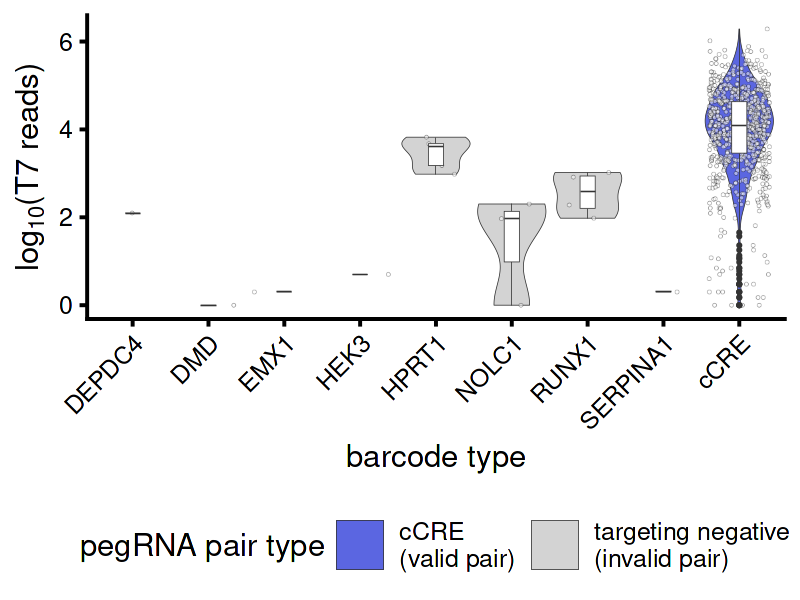

In [21]:
c_ <- c("#5b66e1","lightgrey")


all_reps$type <- ifelse(all_reps$overlapping_CRE %in% pos_oligos$CRE, 
                        all_reps$target,"cCRE")

all_reps$type2 <- ifelse(all_reps$overlapping_CRE %in% pos_oligos$CRE, 
                               "targeting negative\n(invalid pair)",
                               "cCRE\n(valid pair)")

all_reps <- all_reps[all_reps$valid_pairing == "valid pairing",]
all_reps <- all_reps[order(all_reps$type),]

all_reps$type <- forcats::fct_relevel(all_reps$type, "cCRE", after = Inf)

options(repr.plot.width=4, repr.plot.height=3, repr.plot.res=200)
s.e <- ggplot(all_reps,
       aes(x=type,y=log10(n_reads),fill=type2)) + 
       geom_violin(scale="width",drop = FALSE,linewidth=.1) + 
       geom_jitter_rast(width=.4,alpha=.5,size=.5,shape=21,stroke=.1,fill="white") + 
       geom_boxplot(width=.2,fill="white",linewidth=.1,outlier.size=.1) +
       ylab(bquote(log[10]*.("(T7 reads)"))) + 
       theme_classic() +
       theme(
        legend.position="bottom",
        axis.text.x = element_text(angle = 45, hjust = 1)
        ) +
       labs(fill="pegRNA pair type") + 
       xlab("barcode type") +
       scale_fill_manual(values=c_)
s.e

In [22]:
all_reps <- rbind(r1_t7_corrected,
                  r2_t7_corrected,
                  r3_t7_corrected)

all_reps <- aggregate(cbind(n_reads, n_umis) ~ location + barcode + overlapping_CRE +
                             CRE_barcode + valid_pairing + valid_barcode, 
                              data = all_reps, 
                              FUN = mean)

all_reps$type <- ifelse(all_reps$valid_pairing == "valid pairing" & all_reps$overlapping_CRE != "", "valid barcode at\ncorrect cCRE",

                ifelse(all_reps$overlapping_CRE != "" & 
                       all_reps$valid_barcode == "valid barcode" &
                       all_reps$valid_pairing != "valid pairing","valid barcode\nat incorrect cCRE", 

                ifelse(all_reps$overlapping_CRE != "" & 
                       all_reps$valid_barcode == "invalid barcode" ,"invalid barcode at\na targeted cCRE",  

                ifelse(all_reps$overlapping_CRE == "" & all_reps$valid_barcode == "valid barcode",
                       "valid barcode not\nat a targeted cCRE","other"))))

all_reps$type <- factor(all_reps$type, levels = c(
  "valid barcode\nat incorrect cCRE",
  "valid barcode not\nat a targeted cCRE",
  "valid barcode at\ncorrect cCRE"
))


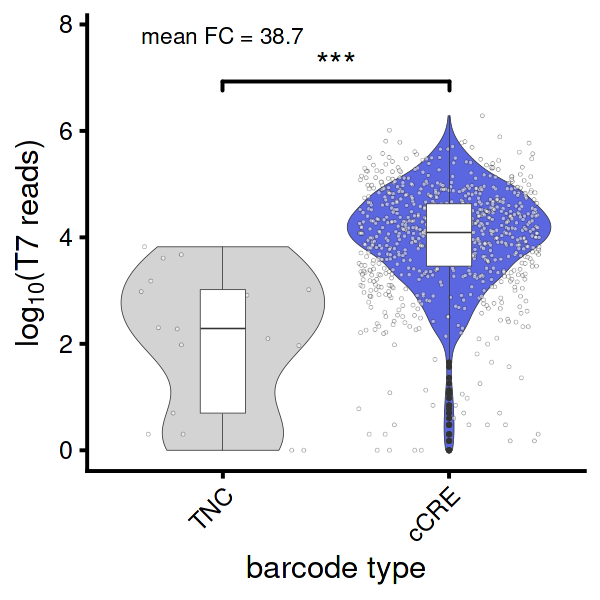

In [23]:
c_ <- rev(c("#5b66e1","lightgrey"))
tmp <- all_reps

tmp$type <- ifelse(tmp$valid_pairing == "valid pairing" & tmp$barcode %in% positive_barcodes,"TNC",
            ifelse(tmp$valid_pairing == "valid pairing","cCRE",  ""    
                  ))

tmp <- tmp[order(tmp$type),]
tmp$type <- forcats::fct_relevel(tmp$type, "cCRE", after = Inf)


fc_mean <- mean(tmp[tmp$type == "cCRE", "n_reads"], na.rm = TRUE) /
           mean(tmp[tmp$type == "TNC", "n_reads"], na.rm = TRUE)


# y-position for annotations in log10 space
df_plot <- tmp[tmp$type != "", ]
y_max <- max(log10(df_plot$n_reads), na.rm = TRUE)

options(repr.plot.width=3, repr.plot.height=3, repr.plot.res=200)

s.f <- ggplot(df_plot, aes(x = type, y = log10(n_reads), fill = type)) +
       geom_violin(scale="width",drop = FALSE,linewidth=.1) + 
       geom_jitter_rast(width=.4,alpha=.5,size=.5,shape=21,stroke=.1,fill="white") + 
       geom_boxplot(width=.2,fill="white",linewidth=.1,outlier.size=.1) +
  geom_signif(
    comparisons = list(c("TNC", "cCRE")),
    test = "wilcox.test",
    map_signif_level = TRUE,
    textsize = 12/.pt,
    y_position = y_max + 0.25,
    tip_length = 0.02
  ) +
  annotate(
    "text",
    x = 1, y = y_max + 1.5,
    label = paste0("mean FC = ", formatC(fc_mean, format = "f", digits = 1)),
    size = 8/.pt
  ) +
  ylab(bquote(log[10]*.("(T7 reads)"))) +
  theme_classic() +
  theme(
    legend.position = "none",
    axis.text.x = element_text(angle = 45, hjust = 1)
  ) +
  labs(fill = "pegRNA pair type") +
  xlab("barcode type") +
  scale_fill_manual(values = c_)
s.f

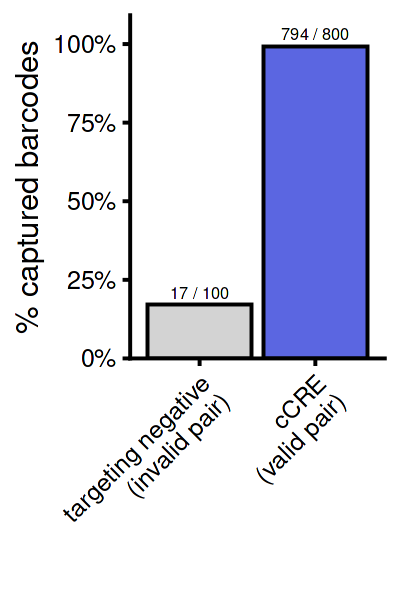

In [24]:
all_reps$type2 <- ifelse(all_reps$valid_pairing == "valid pairing" & all_reps$barcode %in% positive_barcodes,"TNC",
                  ifelse(all_reps$valid_pairing == "valid pairing","cCRE",  "" ))

invalid_tag <- "TNC"

# numerators & denominators
num_invalid   <- sum(all_reps$type2 == invalid_tag)
den_invalid   <- length(positive_barcodes)

num_valid_uniq <- length(unique(all_reps$barcode[all_reps$type2 == "cCRE"]))
den_valid      <- sum(grepl("EH38D", oligos$del_id))

# percentages
pct_invalid       <- 100 * num_invalid   / den_invalid
pct_valid_unique  <- 100 * num_valid_uniq / den_valid


df <- data.frame(
  group      = c("targeting negative\n(invalid pair)", "cCRE\n(valid pair)"),
  numerator  = c(num_invalid, num_valid_uniq),
  denominator= c(den_invalid, den_valid)
)

df$pct   <- 100 * df$numerator / df$denominator
df$label <- paste0(df$numerator, " / ", df$denominator)

c_ <- c("lightgrey","#5b66e1")


df$group <- factor(
  df$group,
  levels = c("targeting negative\n(invalid pair)",
             "cCRE\n(valid pair)")
)

options(repr.plot.width=2, repr.plot.height=3, repr.plot.res=200)
s.g <- ggplot(df, aes(x = group, y = pct, fill = group)) +
  geom_col(width = 0.9, color = "black", show.legend = FALSE) +
  geom_text(aes(label = label), vjust = -0.5, size = 2) +
  scale_y_continuous(labels = function(x) paste0(x, "%"),
                     expand = expansion(mult = c(0, 0.1))) +
       theme_classic() +
       theme(
#            text = element_text(size = 24),
#         axis.line = element_line(color = "black"),
#         panel.grid = element_blank(),
           legend.position="right",
        axis.text.x = element_text(angle = 45, hjust = 1)
        ) +
  ylab("% captured barcodes")+
       scale_fill_manual(values=c_) + xlab("")

s.g

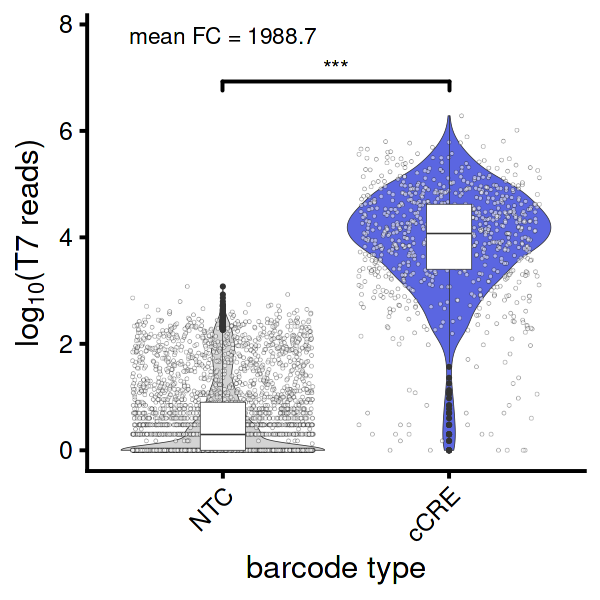

In [25]:
ntc.barcodes <- oligos[grepl("NTC",oligos$del_id) == TRUE,]$barcode

all_reps <- rbind(r1_t7_corrected,
                  r2_t7_corrected,
                  r3_t7_corrected)

all_reps <- aggregate(cbind(n_reads, n_umis) ~ location + barcode + overlapping_CRE +
                             CRE_barcode + valid_pairing + valid_barcode,
                      data = all_reps,
                      FUN = mean)

c_ <- rev(c("#5b66e1","lightgrey"))
tmp <- all_reps

tmp$type <- ifelse(tmp$overlapping_CRE == "" & tmp$barcode %in% ntc.barcodes, "NTC",
            ifelse(tmp$valid_pairing == "valid pairing", "cCRE", ""))

tmp <- tmp[order(tmp$type), ]
tmp$type <- forcats::fct_relevel(tmp$type, "cCRE", after = Inf)

df_plot <- tmp[tmp$type != "", ]

# mean fold-change on raw counts (not log10)
fc_mean <- mean(df_plot[df_plot$type == "cCRE", "n_reads"], na.rm = TRUE) /
           mean(df_plot[df_plot$type == "NTC", "n_reads"], na.rm = TRUE)

# y-position for annotations in log10 space
y_max <- max(log10(df_plot$n_reads), na.rm = TRUE)

options(repr.plot.width=3, repr.plot.height=3, repr.plot.res=200)
s.a <- ggplot(df_plot, aes(x = type, y = log10(n_reads), fill = type)) +
       geom_violin(scale="width",drop = FALSE,linewidth=.1) + 
       geom_jitter_rast(width=.4,alpha=.5,size=.5,shape=21,stroke=.1,fill="white") + 
       geom_boxplot(width=.2,fill="white",linewidth=.1,outlier.size=.1) +
  geom_signif(
    comparisons = list(c("NTC", "cCRE")),
    test = "wilcox.test",
    map_signif_level = TRUE,
    textsize = 8/.pt,
    y_position = y_max + 0.25,
    tip_length = 0.02
  ) +
  annotate(
    "text",
    x = 1, y = y_max + 1.5,
    label = paste0("mean FC = ", formatC(fc_mean, format = "f", digits = 1)),
    size = 8/.pt
  ) +
  ylab(bquote(log[10]*.("(T7 reads)"))) +
  theme_classic() +
  theme(
    legend.position = "none",
    axis.text.x = element_text(angle = 45, hjust = 1)
  ) +
  labs(fill = "pegRNA pair type") +
  xlab("barcode type") +
  scale_fill_manual(values = c_)

s.a

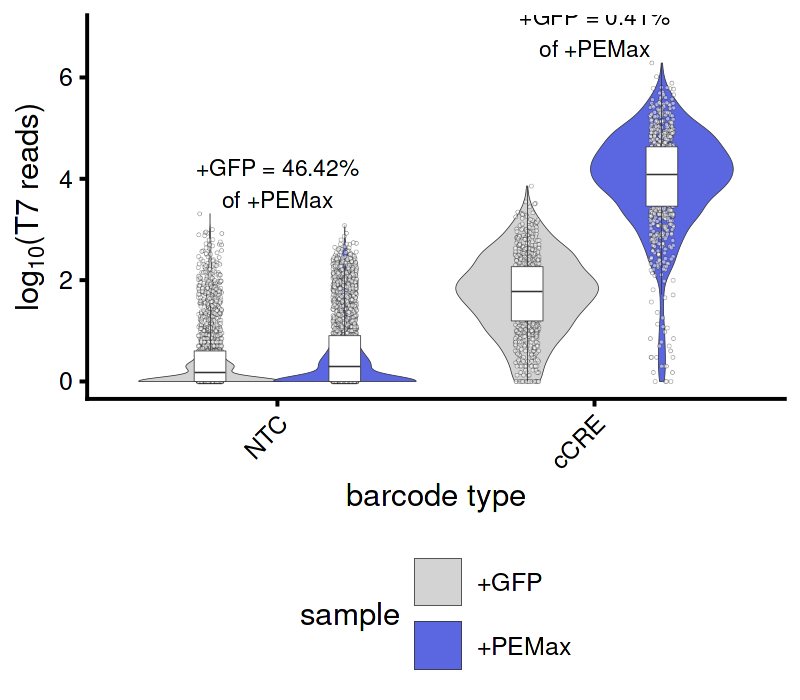

In [26]:
all_reps <- rbind(r1_t7_corrected,
                  r2_t7_corrected,
                  r3_t7_corrected)

all_reps <- aggregate(cbind(n_reads, n_umis) ~ location + barcode + overlapping_CRE +
                             CRE_barcode + valid_pairing + valid_barcode, 
                              data = all_reps, 
                              FUN = mean)
all_reps$sample <- "+PEMax"

n_all_reps <- rbind(n1_t7_corrected,
                  n2_t7_corrected,
                  n3_t7_corrected)

n_all_reps <- aggregate(cbind(n_reads, n_umis) ~ location + barcode + overlapping_CRE +
                             CRE_barcode + valid_pairing + valid_barcode, 
                              data = n_all_reps, 
                              FUN = mean)
n_all_reps$sample <- "+GFP"

c_ <- rev(c("#5b66e1","lightgrey"))

tmp <- rbind(all_reps, n_all_reps)

tmp$type <- ifelse(tmp$overlapping_CRE == "" & tmp$barcode %in% ntc.barcodes, "NTC",
            ifelse(tmp$valid_pairing == "valid pairing" & !(tmp$barcode %in% positive_barcodes), "cCRE", ""))
tmp$type <- forcats::fct_relevel(tmp$type, "cCRE", after = Inf)
df_plot <- tmp[tmp$type != "", ]

# % carryover (+GFP as % of +PEMax), computed separately for CRE and NTC
pct_cre <- 100 * sum(df_plot[df_plot$sample == "+GFP" & df_plot$type == "cCRE", "n_reads"], na.rm=TRUE) /
                 sum(df_plot[df_plot$sample == "+PEMax" & df_plot$type == "cCRE", "n_reads"], na.rm=TRUE)

pct_ntc <- 100 * sum(df_plot[df_plot$sample == "+GFP" & df_plot$type == "NTC", "n_reads"], na.rm=TRUE) /
                 sum(df_plot[df_plot$sample == "+PEMax" & df_plot$type == "NTC", "n_reads"], na.rm=TRUE)

# y positions above each x group (in log10 space, since you're plotting log10(n_reads))
y_pos <- aggregate(log10(n_reads) ~ type, data = df_plot, FUN = max)
y_pos$y <- y_pos$`log10(n_reads)` + 0.35  # vertical padding; tweak if needed

ann <- merge(
  y_pos[, c("type","y")],
  data.frame(type = c("cCRE","NTC"), pct = c(pct_cre, pct_ntc)),
  by = "type", all.x = TRUE
)
ann$label <- paste0("+GFP = ", formatC(ann$pct, format="f", digits=2), "%\nof +PEMax")

pd <- position_dodge(width = 0.85)

options(repr.plot.width=4, repr.plot.height=3.5, repr.plot.res=200)
s.d <- ggplot(df_plot,
       aes(x = type, y = log10(n_reads),
           fill = sample, group = interaction(sample, type))) +
  geom_violin(scale = "width", position = pd, trim = TRUE,linewidth=.1) +
  geom_point_rast(position = position_jitterdodge(jitter.width = 0.15, dodge.width = 0.85)
                  ,alpha=.5,size=.5,shape=21,stroke=.1,fill="white") +
  geom_boxplot(position = pd, outlier.shape = NA, width=.2,fill="white",linewidth=.1,outlier.size=.1) +
  geom_text(data = ann,
            aes(x = type, y = y+.25, label = label),
            inherit.aes = FALSE, size = 8/.pt) +
  ylab(bquote(log[10]*.("(T7 reads)"))) +
  xlab("barcode type") +
  scale_fill_manual(values = c_) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "bottom"
  ) +
guides(fill = guide_legend(nrow = 2, override.aes = list(size = 4)))

s.d

In [27]:
100 * sum(df_plot[df_plot$sample == "+GFP" & df_plot$type == "cCRE", "n_reads"], na.rm=TRUE) /
                 sum(df_plot[df_plot$sample == "+PEMax" & df_plot$type == "cCRE", "n_reads"], na.rm=TRUE)

100 * sum(df_plot[df_plot$sample == "+GFP" & df_plot$type == "NTC", "n_reads"], na.rm=TRUE) /
                 sum(df_plot[df_plot$sample == "+PEMax" & df_plot$type == "NTC", "n_reads"], na.rm=TRUE)

[1] 0.4104804

[1] 46.4185

In [28]:
## Subset each replicate first
r1 <- r1_t7_corrected[r1_t7_corrected$overlapping_CRE == "" & r1_t7_corrected$barcode %in% ntc.barcodes, ]

r2 <- r2_t7_corrected[r2_t7_corrected$overlapping_CRE == "" & r2_t7_corrected$barcode %in% ntc.barcodes, ]

r3 <- r3_t7_corrected[r3_t7_corrected$overlapping_CRE == "" & r3_t7_corrected$barcode %in% ntc.barcodes, ]

## Make a CRE_barcode (or location_barcode) key
r1$CRE_barcode <- paste0(r1$location, "_", r1$barcode)
r2$CRE_barcode <- paste0(r2$location, "_", r2$barcode)
r3$CRE_barcode <- paste0(r3$location, "_", r3$barcode)

## Keep just the key + counts; rename columns to be rep-specific
r1 <- r1[, c("CRE_barcode", "n_reads")]
colnames(r1)[2] <- "n_reads.r1"

r2 <- r2[, c("CRE_barcode", "n_reads")]
colnames(r2)[2] <- "n_reads.r2"

r3 <- r3[, c("CRE_barcode", "n_reads")]
colnames(r3)[2] <- "n_reads.r3"

## Full outer join across all three reps
merged_df <- Reduce(function(x, y) merge(x, y, by = "CRE_barcode", all = TRUE),
                    list(r1, r2, r3))

## Replace NA with 0 for the count columns
count_cols <- grep("^n_reads", colnames(merged_df))
merged_df[, count_cols][is.na(merged_df[, count_cols])] <- 0

## Add a column with number of replicates it was detected in
## (i.e. how many starting dfs it appeared in)
merged_df$n_reps_detected <- rowSums(merged_df[, count_cols] > 0)

merged_df$n_reads.combined <- rowSums(merged_df[, count_cols])

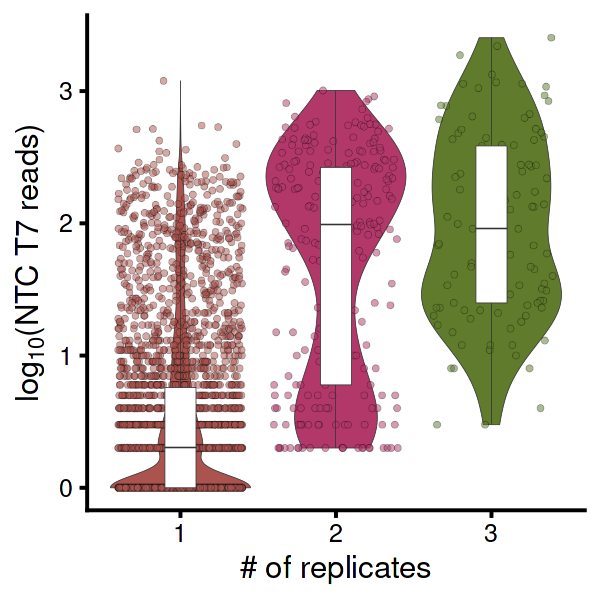

In [29]:
merged_df$n_reps_detected <- as.character(merged_df$n_reps_detected)

set.seed(8)
c_ <- c(
  "#62c251", "#aa4ac1", "#a8b635", "#5b66e1", "#d7a336", "#417eed",
  "#d97f2e", "#9b67e1", "#47963c", "#cf43a8", "#54c79a", "#e44586",
  "#317341", "#d980dd", "#5f7b2b", "#5553b7", "#8db870", "#a9519c",
  "#409775", "#d34250", "#42c0c7", "#ce4c2b", "#4d85d5", "#beaa62",
  "#8d82dd", "#79702a", "#7a559d", "#9c642e", "#56a7d9", "#e58e6e",
  "#4769a2", "#ab544f", "#a19ee0", "#b2386a", "#cc8ec7", "#994f72",
  "#e4819f"
)


options(repr.plot.width=3, repr.plot.height=3, repr.plot.res=200)
s.b <- ggplot(merged_df, aes(x = factor(n_reps_detected), 
                      y = log10(n_reads.combined),
                      fill=n_reps_detected)) +
  geom_violin(scale="width",drop = FALSE,linewidth=.1) +
  geom_point_rast(size = 1,shape=21,alpha=.5,stroke=.1, 
              position = position_jitter(width = 0.4, height = 0)) +

  geom_boxplot(outlier.shape = NA,width=.2,fill="white",linewidth=.1,outlier.size=.1) +
  theme_classic() +
  theme(
        legend.position="none"
  ) + 
  scale_fill_manual(values=sample(c_,3)) +
  xlab("# of replicates") + 
  ylab(bquote(log[10]*.("(NTC T7 reads)")))
s.b

In [30]:
100*nrow(merged_df[merged_df$n_reps_detected == 1,]) / nrow(merged_df)

[1] 90.21059

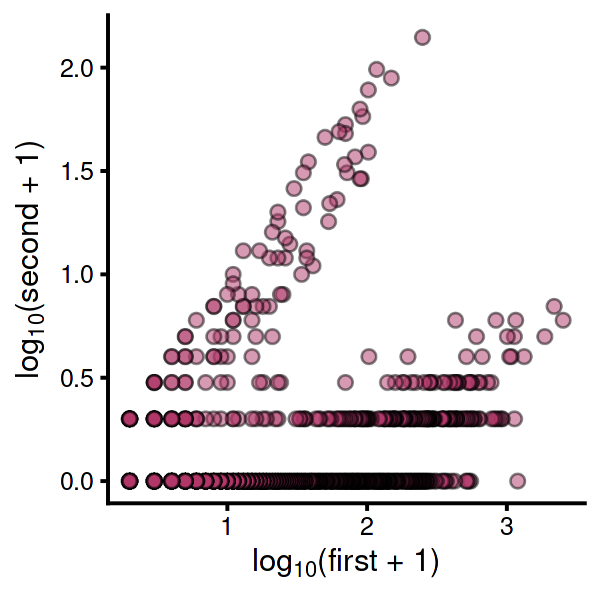

In [31]:
top_out <- as.data.frame(matrix(ncol=0,nrow=0))
for (barcode in unique(merged_df$CRE_barcode)) {
    r1 <- sum(merged_df[merged_df$CRE_barcode == barcode,]$n_reads.r1)
    r2 <- sum(merged_df[merged_df$CRE_barcode == barcode,]$n_reads.r2)
    r3 <- sum(merged_df[merged_df$CRE_barcode == barcode,]$n_reads.r3)

    reads <- c(r1, r2, r3)

    # sort descending
    reads <- sort(reads, decreasing = TRUE)

    # Now the top two values are:
    top <- head(reads, 2)
    
    if (length(top) == 1) {top <- c(top,0)}
    
    top_out <- rbind(top_out,c(barcode,top))
}
colnames(top_out) <- c("CRE_barcode","first","second")
top_out$first <- as.numeric(top_out$first)
top_out$second <- as.numeric(top_out$second)

top_out <- top_out[order(-top_out$first),]

s.c <- ggplot(top_out[order(-top_out$first),],aes(x=log10(first+1),y=log10(second+1))) + 
      geom_point_rast(shape=21,size=2,alpha=.5,fill="#b2386a") +        
      theme_classic() +
      xlab(bquote(log[10]*.("(first + 1)"))) + 
      ylab(bquote(log[10]*.("(second + 1)")))

s.c

In [32]:
layout <- 'ABCC
           DEFG
           '

final <- s.a + s.b + s.e + s.c + s.d + s.f + s.g + 
        plot_layout(design = layout) #+ 
        #plot_annotation(tag_levels = 'A') 

options(repr.plot.width=24, repr.plot.height=16, repr.plot.res=200)
final

# ggsave('SuppFig3_panels.pdf', 
#        plot = final, width = 190, height = 190, 
#        useDingbats = F, units = 'mm', device = 'pdf')

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”


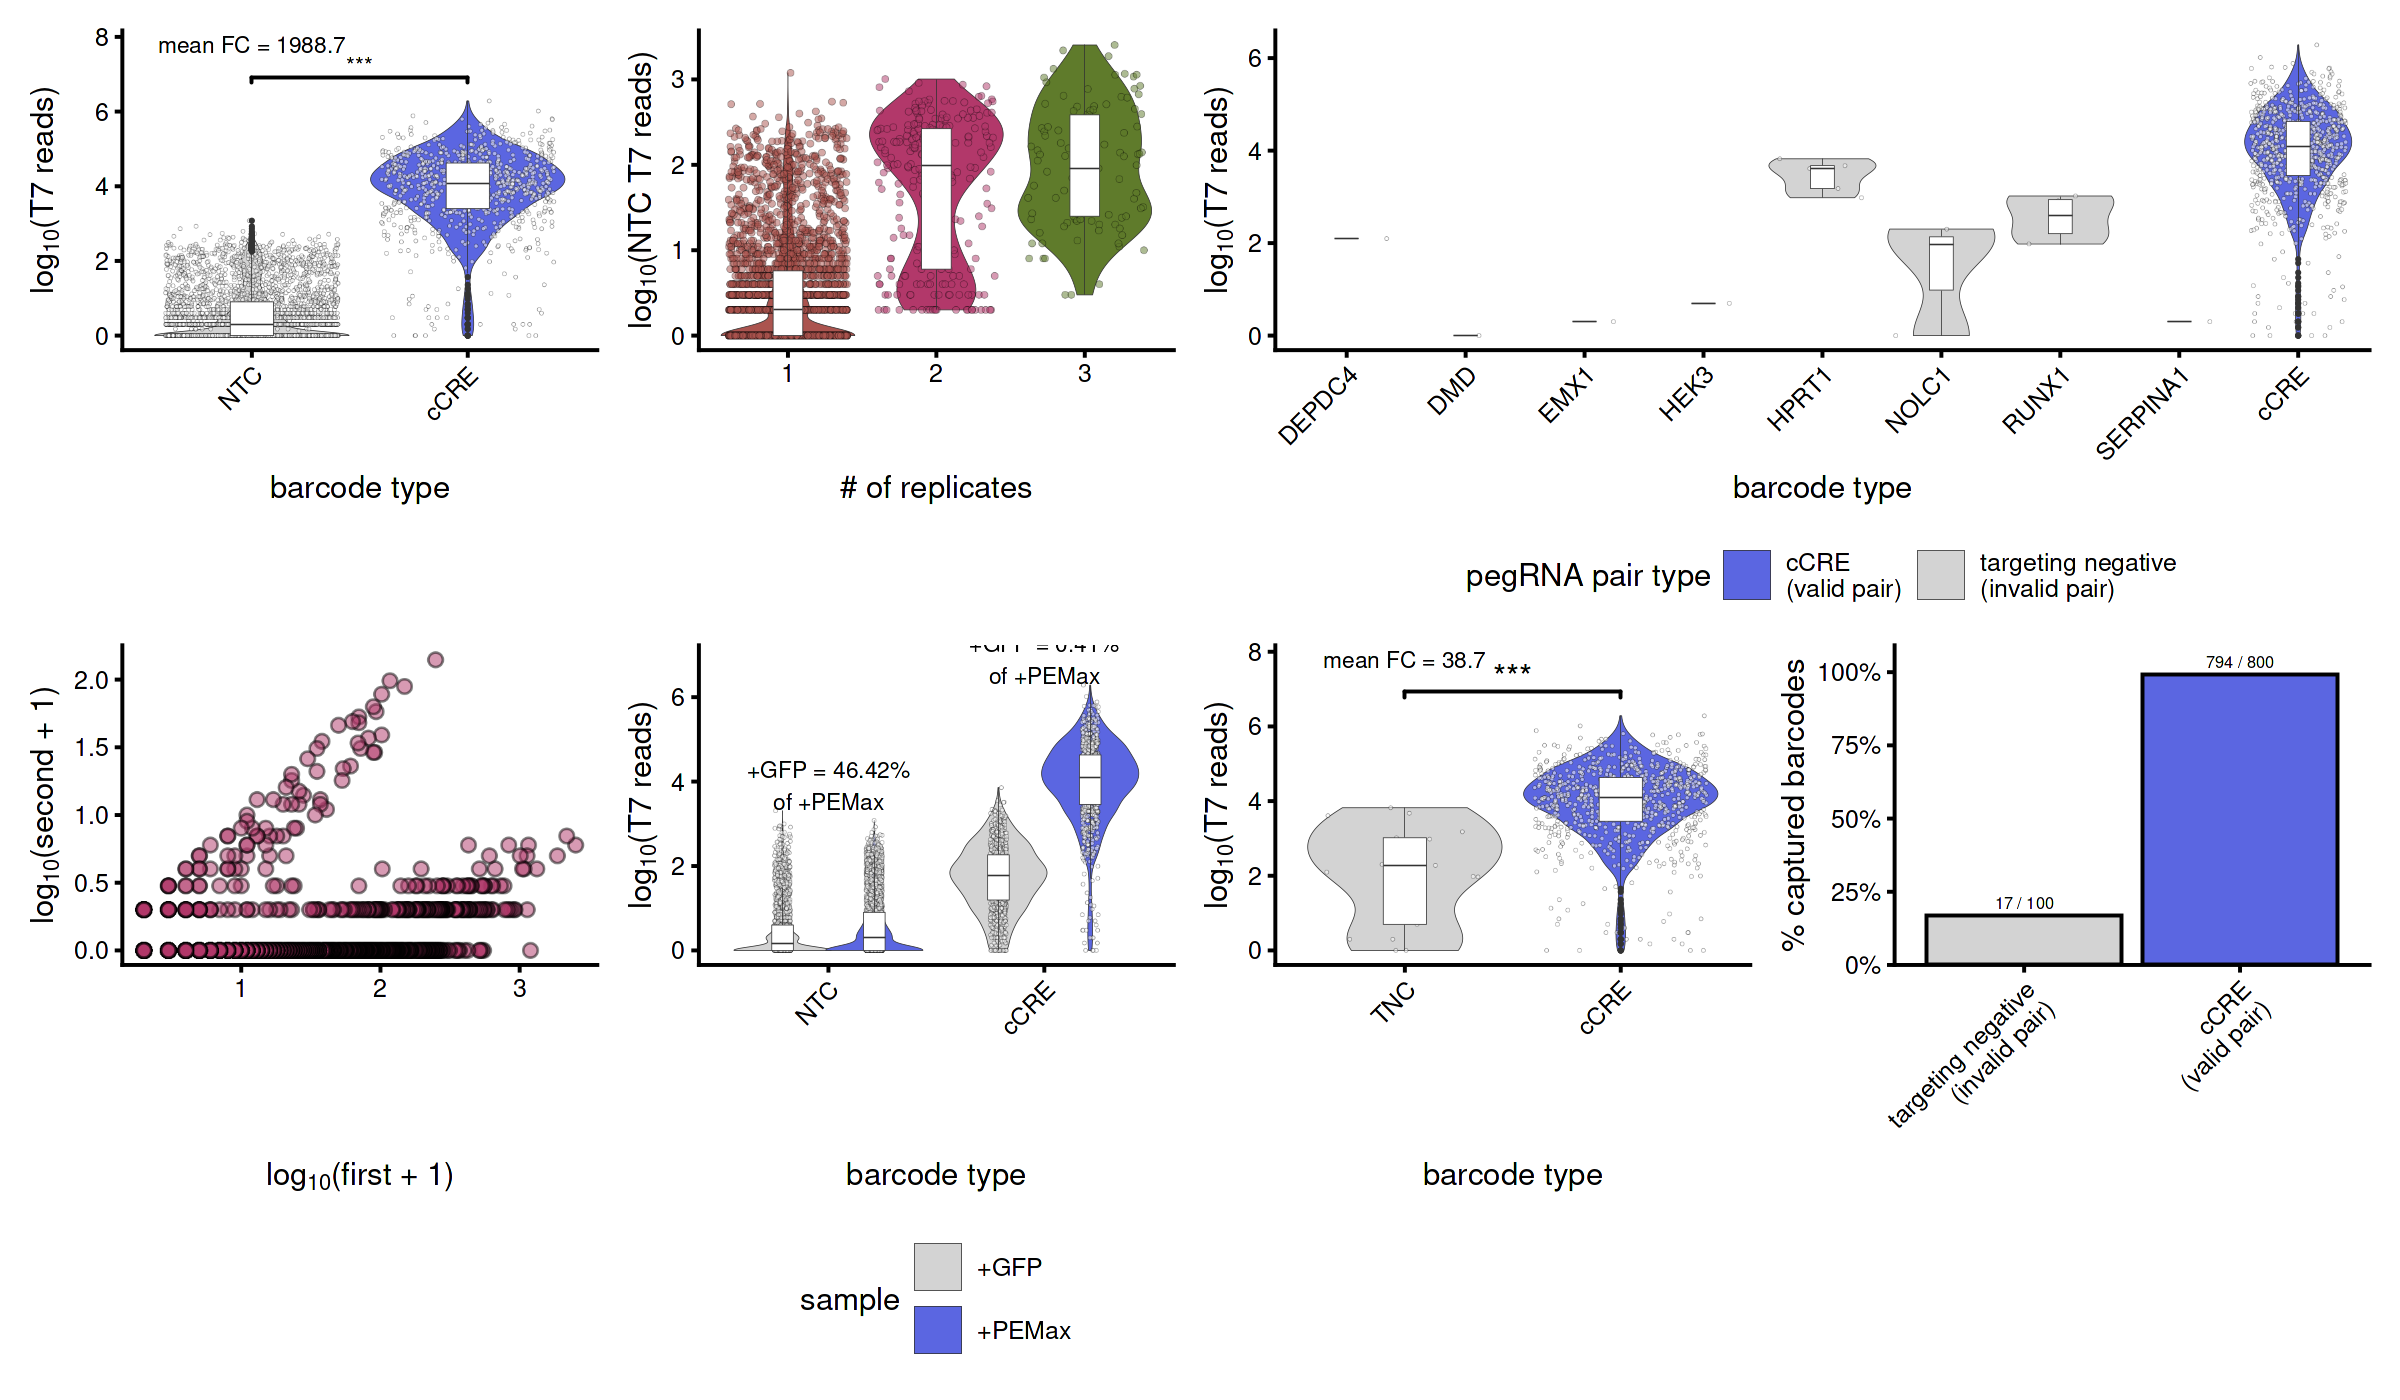

In [33]:
layout <- "
ABCC
DEFG
"

final <- patchwork::wrap_plots(
  A = s.a,
  B = s.b,
  C = s.e,
  D = s.c,
  E = s.d,
  F = s.f,
  G = s.g,
  design = layout
)

options(
  repr.plot.width = 12,
  repr.plot.height = 7,
  repr.plot.res = 200
)

print(final)

In [34]:
ggsave(final,
       file = '../figures/SuppFig6.pdf', 
       width = 210, 
       height = 170,
       units = 'mm')

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”


In [ ]:
sessionInfo()